In [3]:
import pandas as pd
import numpy as np
import scipy.integrate
scipy.integrate.trapz = np.trapz
import plotly.express as px
import plotly.graph_objects as go
from turtle import title
from plotly.subplots import make_subplots
import plotly.tools as tls
from aimstools import BandStructure
from aimstools.bandstructures import BandStructure as BS
#from aimstools.density_of_states import SpeciesProjectedDOS
#from aimstools.density_of_states import AtomProjectedDOS as APD
from aimstools import DensityOfStates as DOS
from matplotlib import gridspec
import matplotlib.pyplot as plt
from inspect import signature

In [4]:
bs_0 = BS("/mnt/d/BPN/AIMS-run/strain/Strain-x/0.0%/input_files_HSE06_tight/input_files/")
dos_0 = DOS("/mnt/d/BPN/AIMS-run/strain/Strain-x/0.0%/input_files_HSE06_tight/input_files/")
bs_NT_zigzag_0 = BS("/mnt/d/BPN/AIMS-run/nanotubes/zigzag/strain/0.0%/input_files_HSE06_inter/input_files")
bs_NT_armchair_0 = BS("/mnt/d/BPN/AIMS-run/nanotubes/armchair/strain/0.0%/input_files_HSE06_inter/input_files")
bs_NR_zigzag_0 = BS("/mnt/d/BPN/AIMS-run/ribbons/zigzag/strain/0.0%/input_files_HSE06_inter/input_files")
bs_NR_armchair_0 = BS("/mnt/d/BPN/AIMS-run/ribbons/armchair/strain/0.0%/input_files_HSE06_inter/input_files")
#atoms_dos_0 = APD("/mnt/d/BPN/AIMS-run/strain/Strain-x/0.0%/input_files_HSE06_tight/input_files/")

INFO     Found results for total density of states.

In [5]:
bs_NR_armchair_0.get_properties()

INFO     Analyzing                                                                                                 
         RegularBandStructure(outputfile=PosixPath('/mnt/d/BPN/AIMS-run/ribbons/armchair/strain/0.0%/input_files_HS
         E06_inter/input_files/aims.out'), spin_orbit_coupling=False) ...

INFO     The band structure has been calculated without spin-orbit-coupling.

INFO     The band gap from the output file is 0.0775 eV large.

INFO     The system appears metallic.

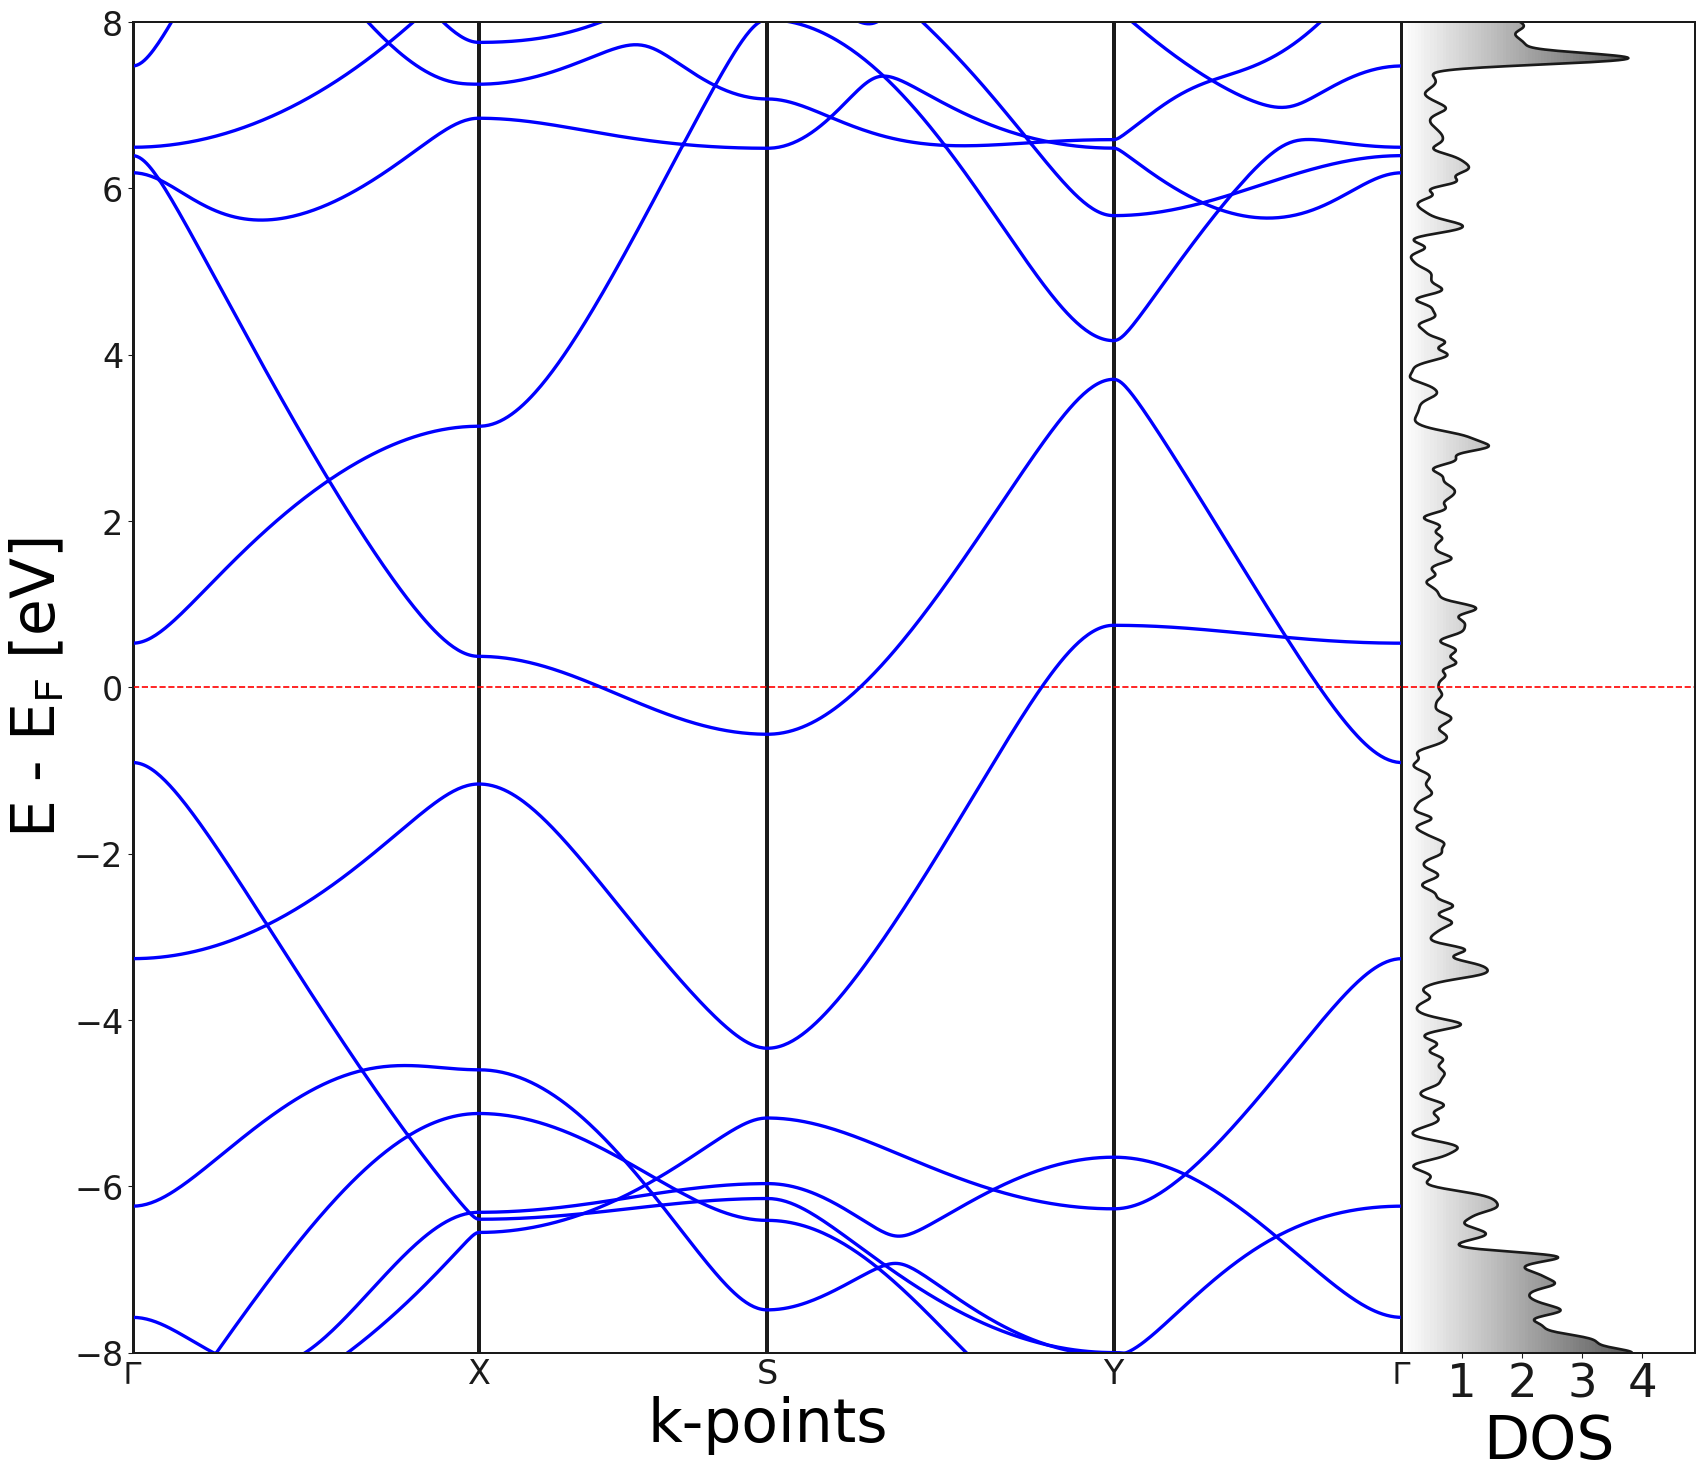

In [42]:
fig = plt.figure(constrained_layout=False, figsize=(21, 18))
spec = gridspec.GridSpec(ncols=2, nrows=1, figure=fig, width_ratios=[3.25, 0.75], wspace=0)

plt.rcParams.update({
    "font.size": 50,           # base font size
    "axes.labelsize": 45,      # x/y labels
    "xtick.labelsize": 35,     # tick labels
    "ytick.labelsize": 35,
    "legend.fontsize": 35
})

ax1 = fig.add_subplot(spec[0])
ax1 = bs_0.plot(axes=ax1, 
              color="blue", 
              main=True, 
              window = (-8 , 8) , 
              fermi_level_color =  "red",
              fermi_level_linewidth =  1.25,
              grid_linewidth = 3, 
              grid_linestyle = '-', 
              bandpath = "GXSYG",
              linewidth = 2.5)

ax1.set_xlabel("k-points")
ax1.tick_params(labelsize=25)

# The options to plot DOS are discussed in another tutorial. Here, we just plot all species.
ax2 = fig.add_subplot(spec[1])
ax2 = dos_0.total_dos.plot(axes=ax2, 
                         window = (-6 , 6),
                         fermi_level_color =  "red",
                         fermi_level_linewidth =  1.25,
                         broadening = 0.05)

#ax2 = atoms_dos_0.plot_contributions(contributions=["C0001","C0002","C0003","C0004","C0005","C0006"], colors=["blue","black","red","orange","purple","cyan"], mode="scatter",axes=ax2)

ax2.set_yticks([])
ax2.set_xticks([1 , 2 , 3 , 4])
ax2.set_ylabel("")
ax2.set_xlabel("DOS")
#fig.suptitle("Band structure + DOS")
#plt.savefig("/mnt/d/BPN/AIMS-run/figures/bands_0%.svg" , dpi=400)
plt.show()

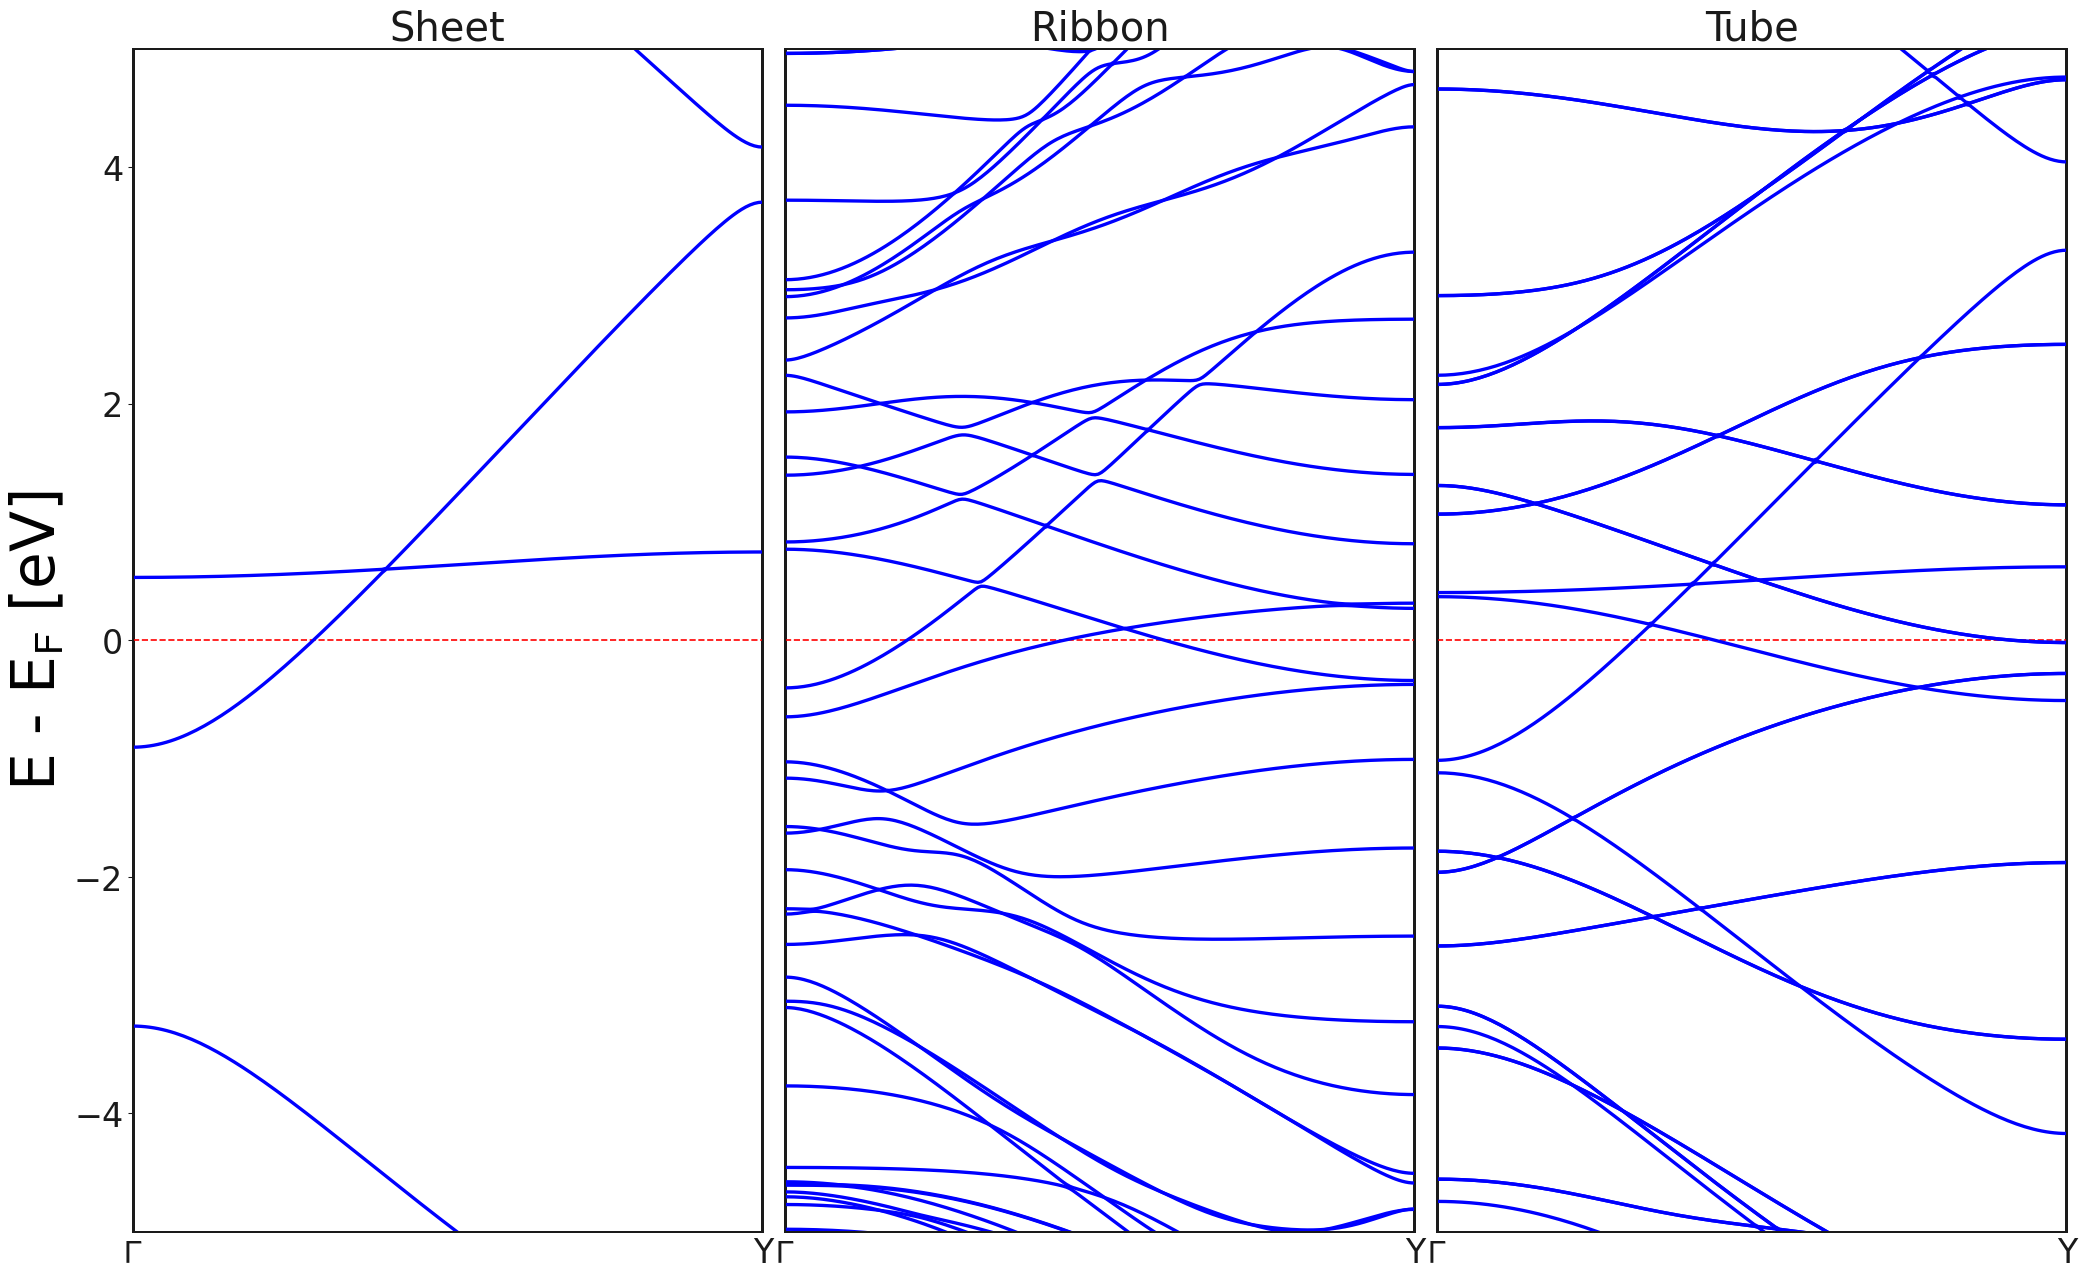

In [43]:
fig = plt.figure(constrained_layout=False, figsize=(26, 16))
spec = gridspec.GridSpec(ncols=3, nrows=1, figure=fig, width_ratios=[1.00, 1.00, 1.00], wspace=0.035)

plt.rcParams.update({
    "font.size": 50,           # base font size
    "axes.labelsize": 45,      # x/y labels
    "xtick.labelsize": 35,     # tick labels
    "ytick.labelsize": 35,
    "legend.fontsize": 35
})

ax1 = fig.add_subplot(spec[0])
ax1 = bs_0.plot(axes=ax1, 
              color="blue", 
              main=True, 
              window = (-5 , 5) , 
              fermi_level_color =  "red",
              fermi_level_linewidth =  1.25,
              grid_linewidth = 3, 
              grid_linestyle = '-', 
              linewidth = 2.5,
              show_bandgap_vertices = False,
              bandpath = "GY")

#ax1.set_xlabel("k-points")
ax1.set_title("Sheet", fontsize=30)
ax1.tick_params(labelsize=25)

ax2 = fig.add_subplot(spec[1])
ax2 = bs_NR_zigzag_0.plot(axes=ax2, 
              color="blue", 
              main=True, 
              window = (-5 , 5) , 
              fermi_level_color =  "red",
              fermi_level_linewidth =  1.25,
              grid_linewidth = 3, 
              grid_linestyle = '-', 
              linewidth = 2.5)
              #bandpath = "GY")

#ax2.set_xlabel("k-points")
ax2.set_title("Ribbon", fontsize=30)
ax2.tick_params(labelsize=25)

ax3 = fig.add_subplot(spec[2])
ax3 = bs_NT_zigzag_0.plot(axes=ax3, 
              color="blue", 
              main=True, 
              window = (-5 , 5) , 
              fermi_level_color =  "red",
              fermi_level_linewidth =  1.25,
              grid_linewidth = 3, 
              grid_linestyle = '-', 
              linewidth = 2.5)
              #bandpath = "GY")

#ax3.set_xlabel("k-points")
ax3.set_title("Tube", fontsize=30)
ax3.tick_params(labelsize=25)

ax2.set_yticks([])
#ax2.set_xticks([])
ax2.set_ylabel("")
#ax2.set_xlabel("")
ax3.set_yticks([])
#ax3.set_xticks([])
ax3.set_ylabel("")
#ax3.set_xlabel("")
#fig.suptitle("Band structure + DOS")
#plt.savefig("/mnt/d/BPN/AIMS-run/figures/bands_0%.svg" , dpi=400)
plt.show()

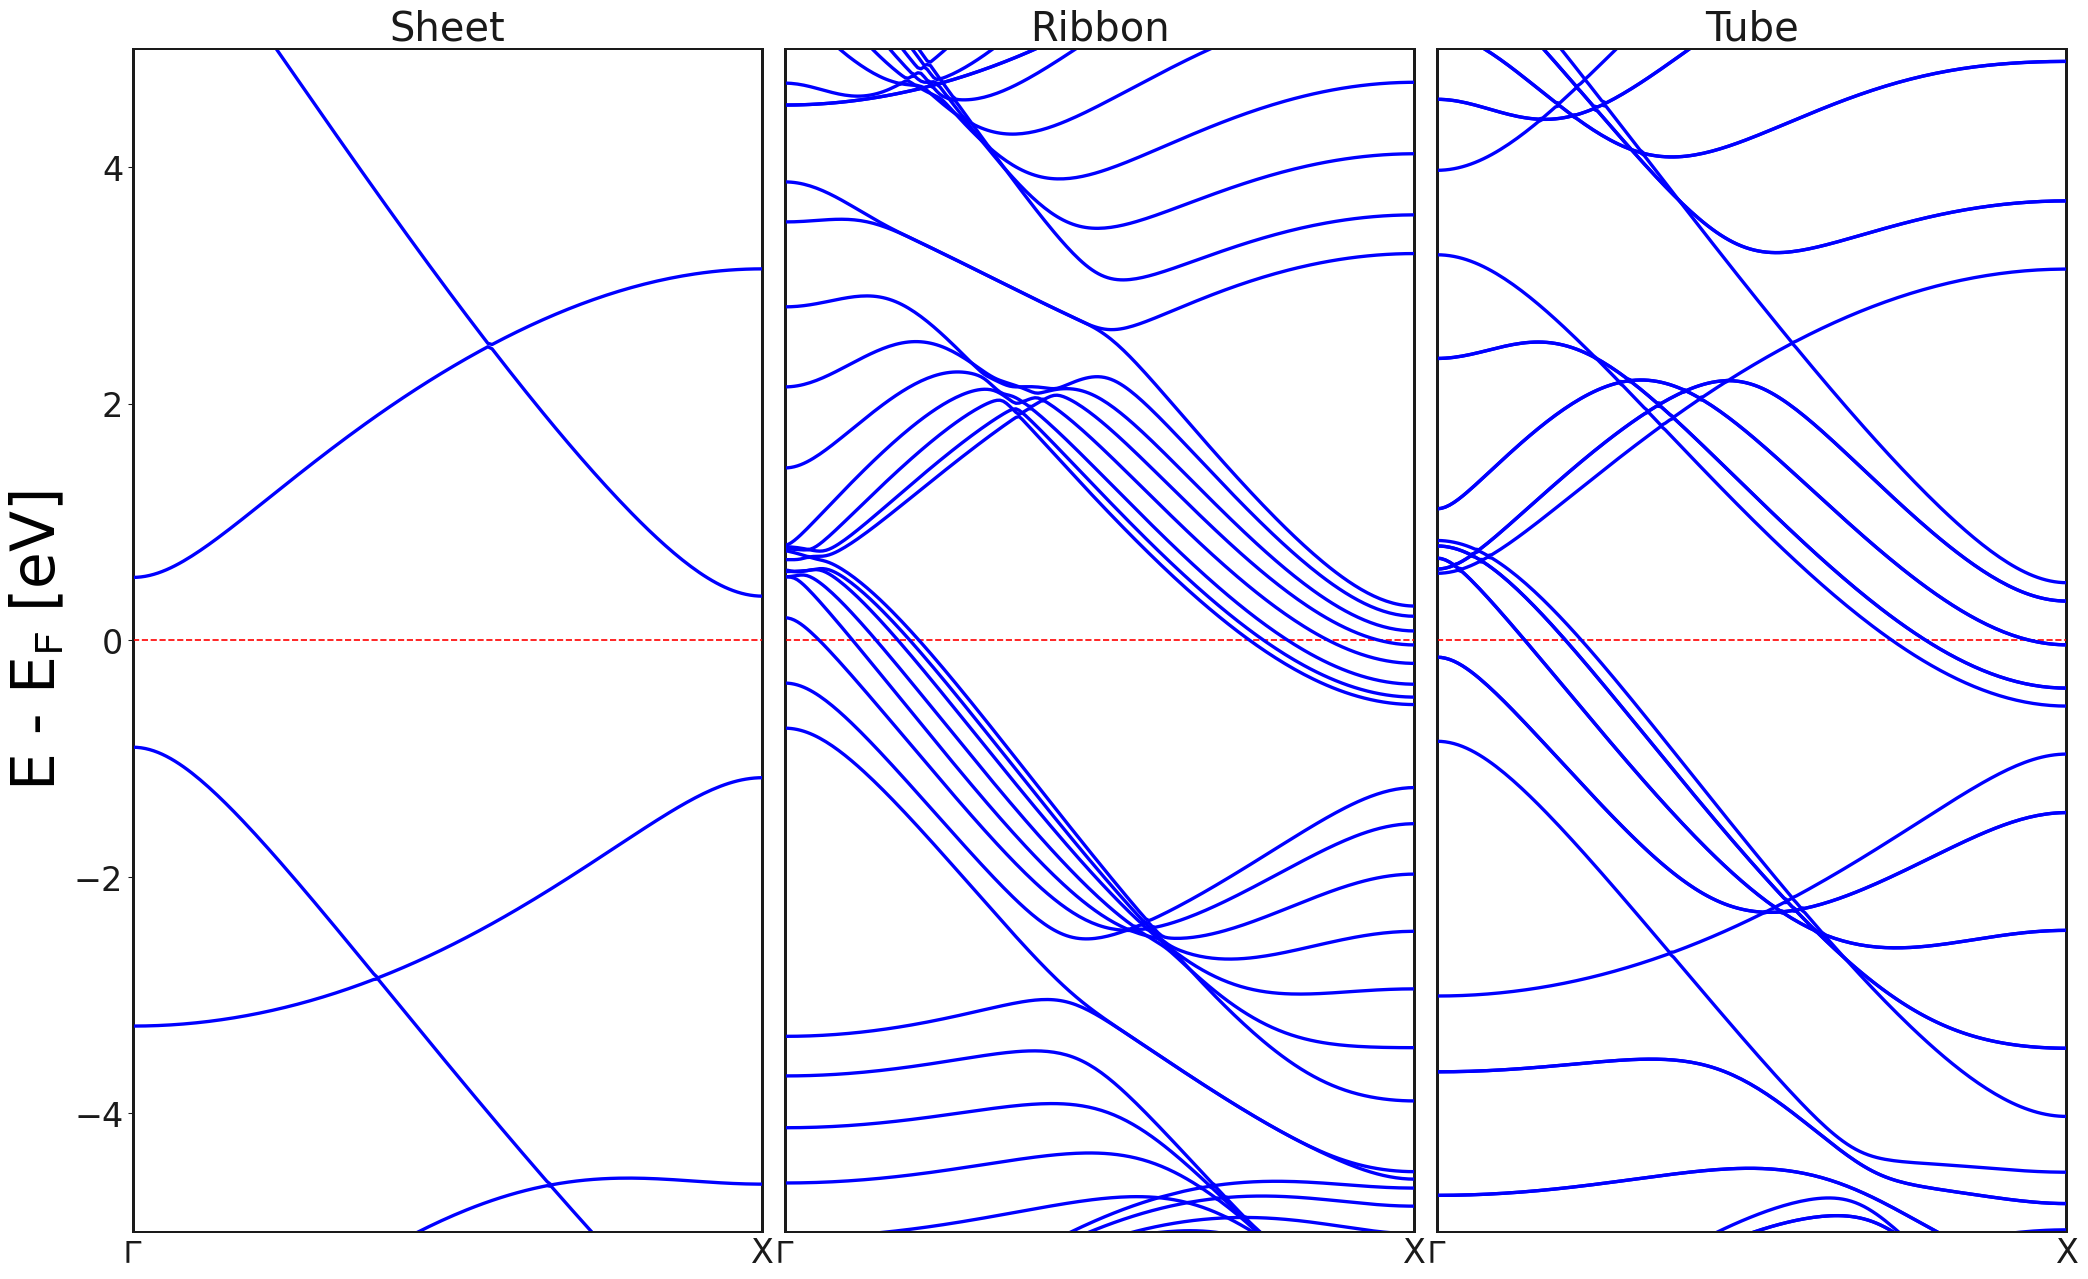

In [44]:
fig = plt.figure(constrained_layout=False, figsize=(26, 16))
spec = gridspec.GridSpec(ncols=3, nrows=1, figure=fig, width_ratios=[1.00, 1.00, 1.00], wspace=0.035)

plt.rcParams.update({
    "font.size": 50,           # base font size
    "axes.labelsize": 45,      # x/y labels
    "xtick.labelsize": 35,     # tick labels
    "ytick.labelsize": 35,
    "legend.fontsize": 35
})

ax1 = fig.add_subplot(spec[0])
ax1 = bs_0.plot(axes=ax1, 
              color="blue", 
              main=True, 
              window = (-5 , 5) , 
              fermi_level_color =  "red",
              fermi_level_linewidth =  1.25,
              grid_linewidth = 3, 
              grid_linestyle = '-', 
              linewidth = 2.5,
              show_bandgap_vertices = False,
              bandpath = "GX")

#ax1.set_xlabel("k-points")
ax1.set_title("Sheet", fontsize=30)
ax1.tick_params(labelsize=25)

ax2 = fig.add_subplot(spec[1])
ax2 = bs_NR_armchair_0.plot(axes=ax2, 
              color="blue", 
              main=True, 
              window = (-5 , 5) , 
              fermi_level_color =  "red",
              fermi_level_linewidth =  1.25,
              grid_linewidth = 3, 
              grid_linestyle = '-', 
              linewidth = 2.5)
              #bandpath = "GY")

#ax2.set_xlabel("k-points")
ax2.set_title("Ribbon", fontsize=30)
ax2.tick_params(labelsize=25)

ax3 = fig.add_subplot(spec[2])
ax3 = bs_NT_armchair_0.plot(axes=ax3, 
              color="blue", 
              main=True, 
              window = (-5 , 5) , 
              fermi_level_color =  "red",
              fermi_level_linewidth =  1.25,
              grid_linewidth = 3, 
              grid_linestyle = '-', 
              linewidth = 2.5)
              #bandpath = "GY")

#ax3.set_xlabel("k-points")
ax3.set_title("Tube", fontsize=30)
ax3.tick_params(labelsize=25)

ax2.set_yticks([])
#ax2.set_xticks([])
ax2.set_ylabel("")
#ax2.set_xlabel("")
ax3.set_yticks([])
#ax3.set_xticks([])
ax3.set_ylabel("")
#ax3.set_xlabel("")
#fig.suptitle("Band structure + DOS")
#plt.savefig("/mnt/d/BPN/AIMS-run/figures/bands_0%.svg" , dpi=400)
plt.show()

In [35]:
bs_9_x = BS("/mnt/d/BPN/AIMS-run/strain/Strain-x/9.0%/input_files_HSE06_tight/input_files/")
dos_9_x = DOS("/mnt/d/BPN/AIMS-run/strain/Strain-x/9.0%/input_files_HSE06_tight/input_files/")

/home/marcelo/miniconda3/lib/python3.12/site-packages/aimstools/structuretools/structure.py:90: FutureWarning:

`get_spacegroup` has been deprecated due to its misleading output. The returned `Spacegroup` object has symmetry operations for a standard setting regardress of the given `Atoms` object. See https://gitlab.com/ase/ase/-/issues/1534 for details. Please use `ase.spacegroup.symmetrize.check_symmetry` or `spglib` directly to get the symmetry operations for the given `Atoms` object.



INFO     Found results for total density of states.

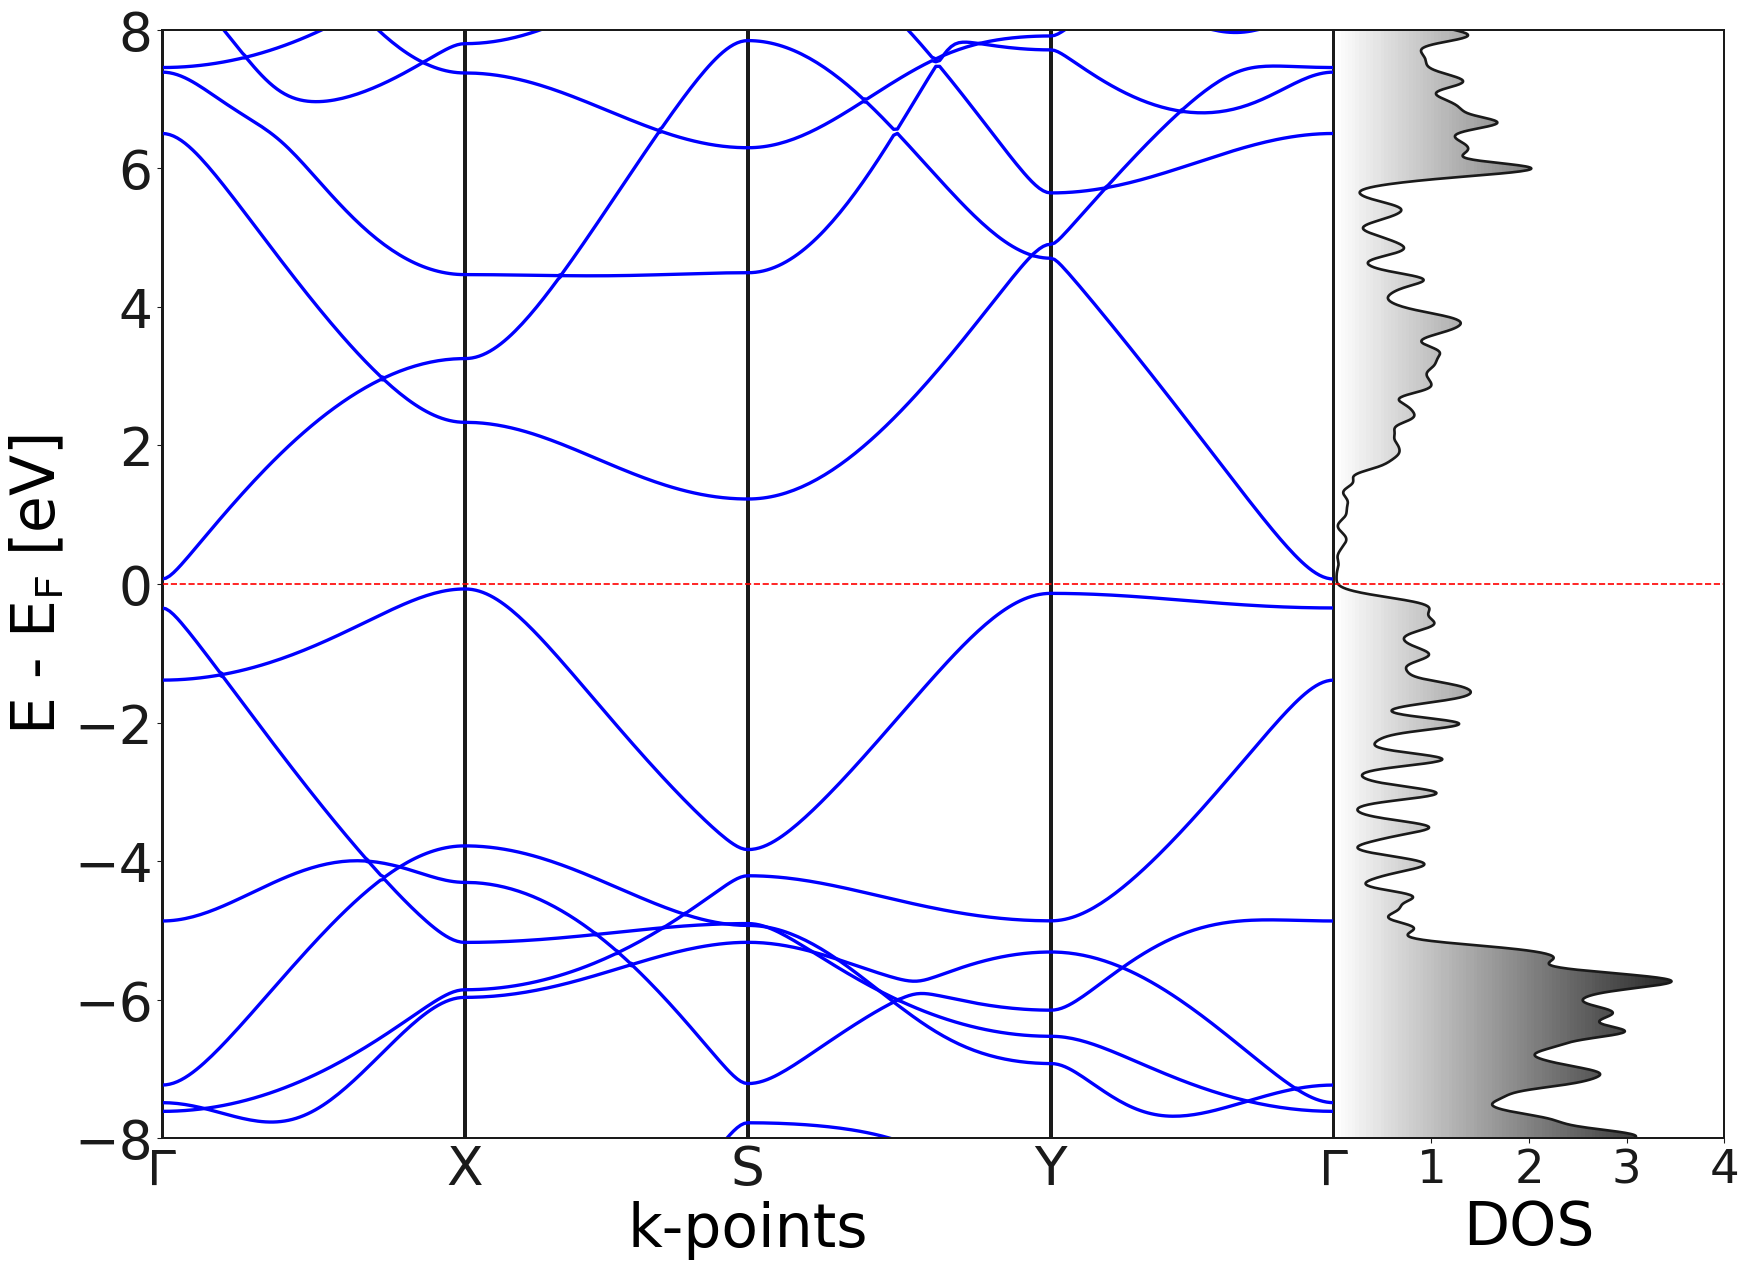

In [45]:
fig = plt.figure(constrained_layout=False, figsize=(21, 15))
spec = gridspec.GridSpec(ncols=2, nrows=1, figure=fig, width_ratios=[3, 1], wspace=0)

plt.rcParams.update({
    "font.size": 50,           # base font size
    "axes.labelsize": 45,      # x/y labels
    "xtick.labelsize": 35,     # tick labels
    "ytick.labelsize": 35,
    "legend.fontsize": 35
})

ax1 = fig.add_subplot(spec[0])
ax1 = bs_9_x.plot(axes=ax1, 
              color="blue", 
              main=True, 
              window = (-8 , 8) , 
              fermi_level_color =  "red",
              fermi_level_linewidth =  1.25,
              grid_linewidth = 3, 
              grid_linestyle = '-', 
              linewidth = 2.5)

ax1.set_xlabel("k-points")
ax1.tick_params(labelsize=40)

# The options to plot DOS are discussed in another tutorial. Here, we just plot all species.
ax2 = fig.add_subplot(spec[1])
ax2 = dos_9_x.total_dos.plot(axes=ax2, 
                         window = (-6 , 6),
                         fermi_level_color =  "red",
                         fermi_level_linewidth =  1.25,
                         broadening = 0.05)

ax2.set_yticks([])
ax2.set_xticks([1 , 2 , 3 , 4])
ax2.set_ylabel("")
ax2.set_xlabel("DOS")
#fig.suptitle("Band structure + DOS")
#plt.savefig("/mnt/d/BPN/AIMS-run/figures/bands_10%_x.svg" , dpi=400)
plt.show()

In [47]:
bs_10_x = BS("/mnt/d/BPN/AIMS-run/strain/Strain-x/10.0%/input_files_HSE06_tight/input_files/")
dos_10_x = DOS("/mnt/d/BPN/AIMS-run/strain/Strain-x/10.0%/input_files_HSE06_tight/input_files/")

/home/marcelo/miniconda3/lib/python3.12/site-packages/aimstools/structuretools/structure.py:90: FutureWarning:

`get_spacegroup` has been deprecated due to its misleading output. The returned `Spacegroup` object has symmetry operations for a standard setting regardress of the given `Atoms` object. See https://gitlab.com/ase/ase/-/issues/1534 for details. Please use `ase.spacegroup.symmetrize.check_symmetry` or `spglib` directly to get the symmetry operations for the given `Atoms` object.



INFO     Found results for total density of states.

INFO     Plotting regular band structure without spin-orbit coupling.

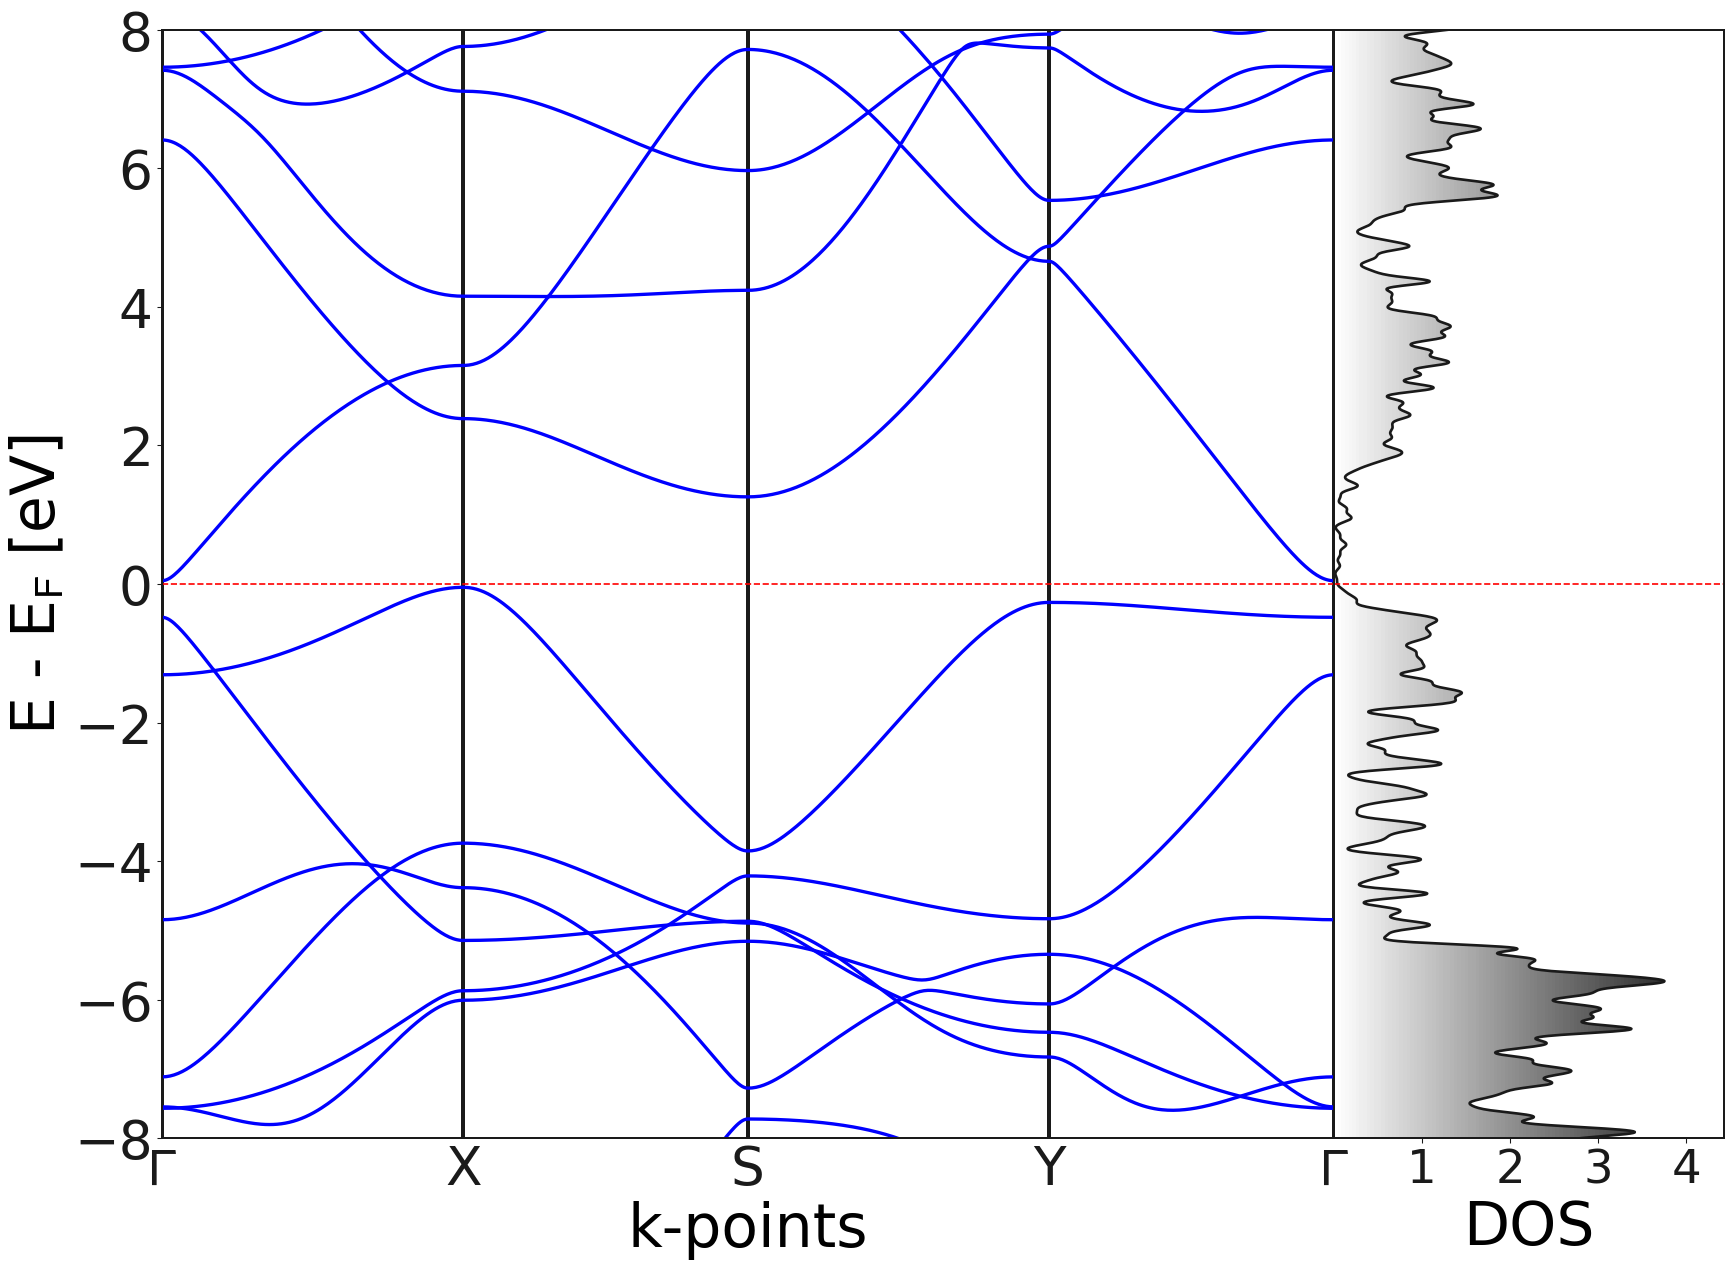

In [48]:
fig = plt.figure(constrained_layout=False, figsize=(21, 15))
spec = gridspec.GridSpec(ncols=2, nrows=1, figure=fig, width_ratios=[3, 1], wspace=0)

plt.rcParams.update({
    "font.size": 50,           # base font size
    "axes.labelsize": 45,      # x/y labels
    "xtick.labelsize": 35,     # tick labels
    "ytick.labelsize": 35,
    "legend.fontsize": 35
})

ax1 = fig.add_subplot(spec[0])
ax1 = bs_10_x.plot(axes=ax1, 
              color="blue", 
              main=True, 
              window = (-8 , 8) , 
              fermi_level_color =  "red",
              fermi_level_linewidth =  1.25,
              grid_linewidth = 3, 
              grid_linestyle = '-', 
              linewidth = 2.5)

ax1.set_xlabel("k-points")
ax1.tick_params(labelsize=40)

# The options to plot DOS are discussed in another tutorial. Here, we just plot all species.
ax2 = fig.add_subplot(spec[1])
ax2 = dos_10_x.total_dos.plot(axes=ax2, 
                         window = (-6 , 6),
                         fermi_level_color =  "red",
                         fermi_level_linewidth =  1.25,
                         broadening = 0.05)

ax2.set_yticks([])
ax2.set_xticks([1 , 2 , 3 , 4])
ax2.set_ylabel("")
ax2.set_xlabel("DOS")
#fig.suptitle("Band structure + DOS")
#plt.savefig("/mnt/d/BPN/AIMS-run/figures/bands_10%_x.svg" , dpi=400)
plt.show()

In [51]:
bs_10_y = BS("/mnt/d/BPN/AIMS-run/strain/Strain-y/10.0%/input_files_HSE06_tight/input_files/")
dos_10_y = DOS("/mnt/d/BPN/AIMS-run/strain/Strain-y/10.0%/input_files_HSE06_tight/input_files/")

/home/marcelo/miniconda3/lib/python3.12/site-packages/aimstools/structuretools/structure.py:90: FutureWarning:

`get_spacegroup` has been deprecated due to its misleading output. The returned `Spacegroup` object has symmetry operations for a standard setting regardress of the given `Atoms` object. See https://gitlab.com/ase/ase/-/issues/1534 for details. Please use `ase.spacegroup.symmetrize.check_symmetry` or `spglib` directly to get the symmetry operations for the given `Atoms` object.



INFO     Found results for total density of states.

INFO     Plotting regular band structure without spin-orbit coupling.

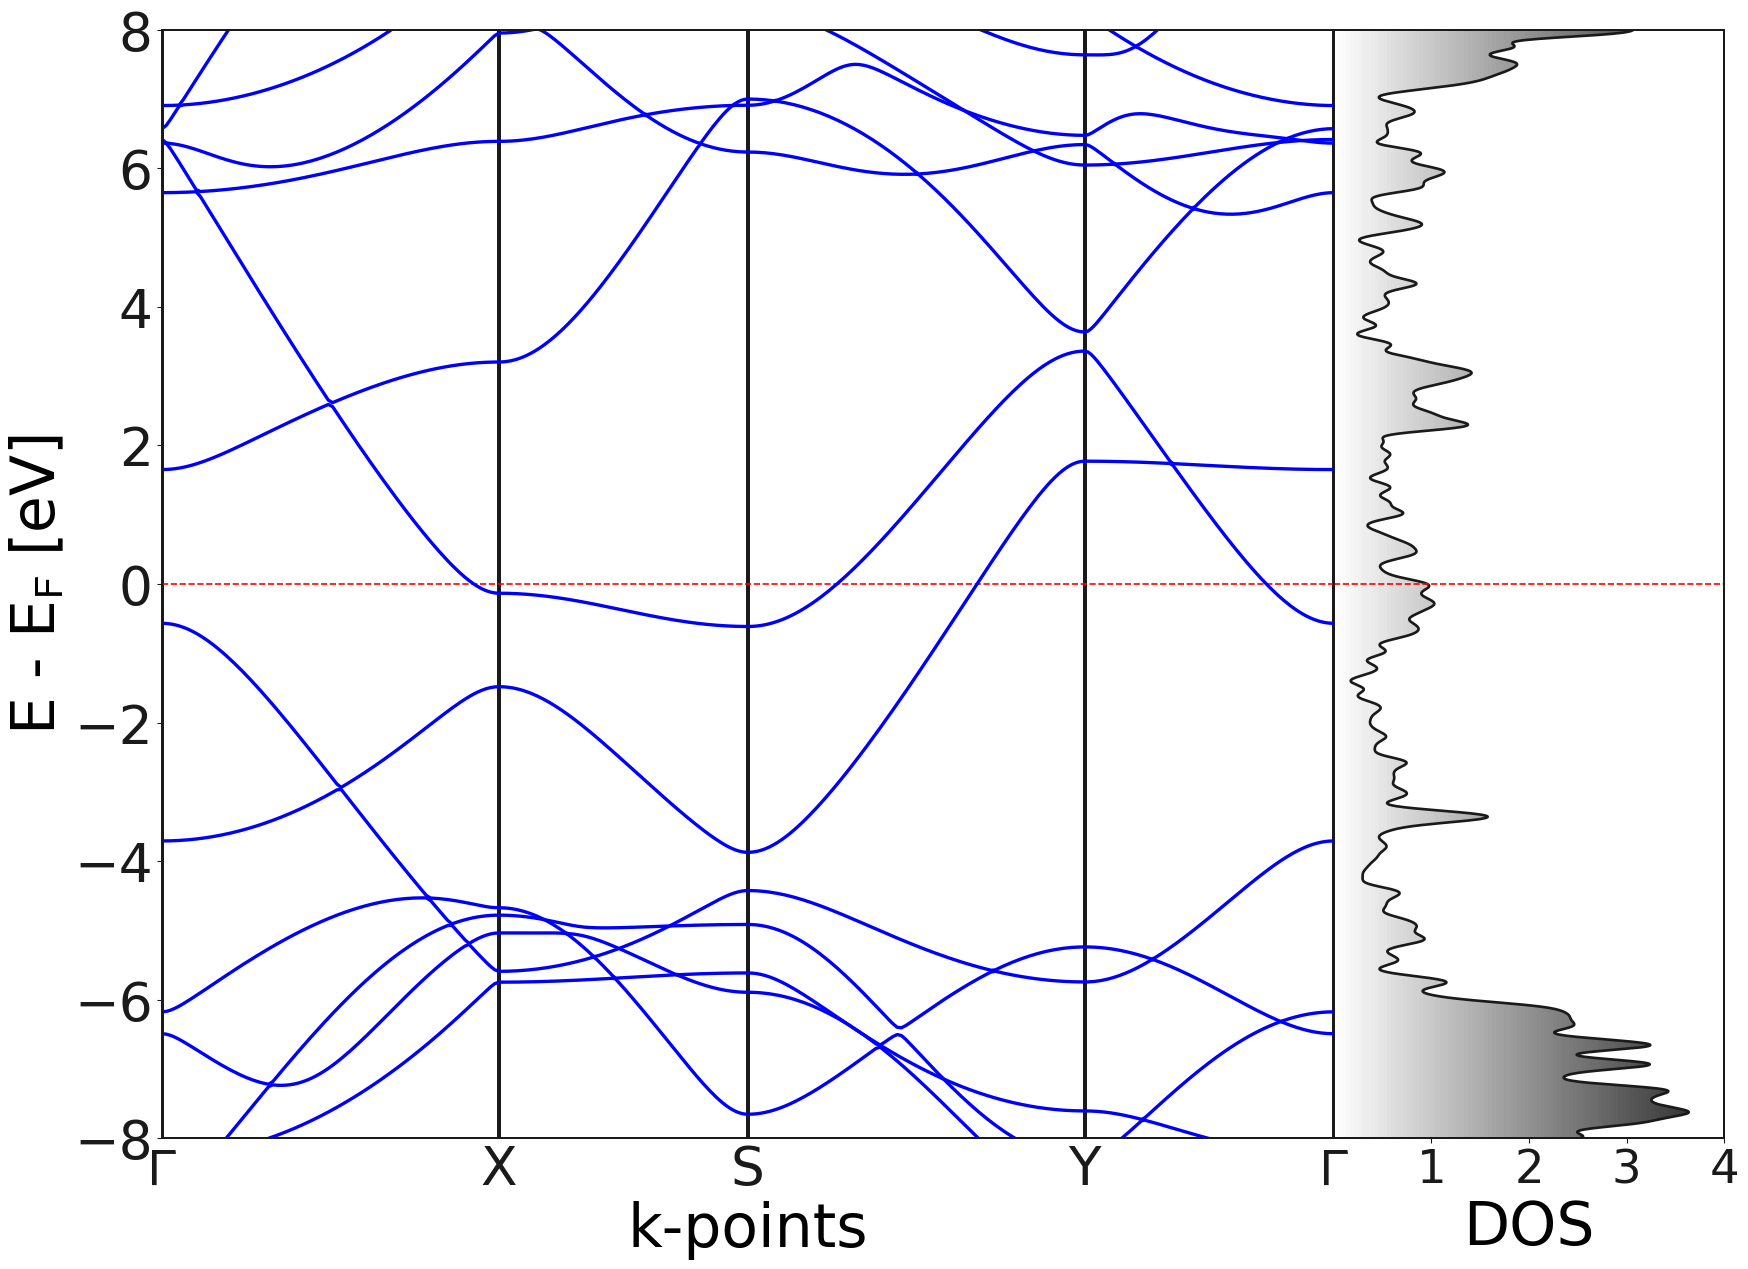

In [52]:
fig = plt.figure(constrained_layout=False, figsize=(21, 15))
spec = gridspec.GridSpec(ncols=2, nrows=1, figure=fig, width_ratios=[3, 1], wspace=0)

plt.rcParams.update({
    "font.size": 50,           # base font size
    "axes.labelsize": 45,      # x/y labels
    "xtick.labelsize": 35,     # tick labels
    "ytick.labelsize": 35,
    "legend.fontsize": 35
})

ax1 = fig.add_subplot(spec[0])
ax1 = bs_10_y.plot(axes=ax1, 
              color="blue", 
              main=True, 
              window = (-8 , 8) , 
              fermi_level_color =  "red",
              fermi_level_linewidth =  1.25,
              grid_linewidth = 3, 
              grid_linestyle = '-', 
              linewidth = 2.5)

ax1.set_xlabel("k-points")
ax1.tick_params(labelsize=40)

# The options to plot DOS are discussed in another tutorial. Here, we just plot all species.
ax2 = fig.add_subplot(spec[1])
ax2 = dos_10_y.total_dos.plot(axes=ax2, 
                         window = (-6 , 6),
                         fermi_level_color =  "red",
                         fermi_level_linewidth =  1.25,
                         broadening = 0.02)

ax2.set_yticks([])
ax2.set_xticks([1 , 2 , 3 , 4])
ax2.set_ylabel("")
ax2.set_xlabel("DOS")
#fig.suptitle("Band structure + DOS")
#plt.savefig("/mnt/d/BPN/AIMS-run/figures/bands_10%_y.svg" , dpi=400)
plt.show()